"""Approximate sin(x) on [-100, 100] with Fourier features and an MLP.

Fourier features make it much easier for the network to represent a highly
oscillatory function than raw x values followed by tanh layers alone.
"""

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

In [2]:
# Reproducability
torch.manual_seed(42)

In [3]:
# ---------------------------------------------------------------------------
# Data
# ---------------------------------------------------------------------------

N = 1000
x = -100.0 + 200.0 * torch.rand(N, 1)
y = torch.sin(x)

indices = torch.randperm(N)
train_size = int(0.8 * N)

x_train = x[indices[:train_size]]
y_train = y[indices[:train_size]]
x_val = x[indices[train_size:]]
y_val = y[indices[train_size:]]


In [4]:
# ---------------------------------------------------------------------------
# Fourier-feature network
# ---------------------------------------------------------------------------

# Work in z in [-1, 1]. Since x = 100z, sin(x) = sin(100z).
# The feature frequencies are chosen in normalized coordinates so that the
# network has access to both low- and high-frequency oscillatory components.
FOURIER_FREQUENCIES = torch.tensor([1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0, 100.0])

class FourierFeatures(nn.Module):
    def __init__(self, frequencies):
        super().__init__()
        self.register_buffer("frequencies", frequencies.reshape(1, -1))

    def forward(self, z):
        angles = z * self.frequencies
        return torch.cat((z, torch.sin(angles), torch.cos(angles)), dim=1)



In [5]:
class SineNet(nn.Module):
    def __init__(self, hidden_width=128):
        super().__init__()
        number_of_features = 1 + 2 * len(FOURIER_FREQUENCIES)

        self.network = nn.Sequential(
            FourierFeatures(FOURIER_FREQUENCIES),
            nn.Linear(number_of_features, hidden_width),
            nn.Tanh(),
            nn.Linear(hidden_width, hidden_width),
            nn.Tanh(),
            nn.Linear(hidden_width, hidden_width),
            nn.Tanh(),
            nn.Linear(hidden_width, 1),
        )

    def forward(self, x):
        # Normalize the original domain [-100, 100] to [-1, 1].
        return self.network(x / 100.0)



In [6]:
model = SineNet()
print(model)


SineNet(
  (network): Sequential(
    (0): FourierFeatures()
    (1): Linear(in_features=17, out_features=128, bias=True)
    (2): Tanh()
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): Tanh()
    (5): Linear(in_features=128, out_features=128, bias=True)
    (6): Tanh()
    (7): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [7]:
# ---------------------------------------------------------------------------
# Training
# ---------------------------------------------------------------------------

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3000
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()

    predictions = model(x_train)
    train_loss = loss_fn(predictions, y_train)

    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_predictions = model(x_val)
        val_loss = loss_fn(val_predictions, y_val)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1:5d} | "
            f"Train Loss: {train_loss.item():.6f} | "
            f"Val Loss: {val_loss.item():.6f}"
        )




Epoch   500 | Train Loss: 0.000035 | Val Loss: 0.000047
Epoch  1000 | Train Loss: 0.000011 | Val Loss: 0.000014
Epoch  1500 | Train Loss: 0.000005 | Val Loss: 0.000006
Epoch  2000 | Train Loss: 0.000092 | Val Loss: 0.000008
Epoch  2500 | Train Loss: 0.000001 | Val Loss: 0.000002
Epoch  3000 | Train Loss: 0.000001 | Val Loss: 0.000001


In [8]:
# ---------------------------------------------------------------------------
# Evaluation inside the training domain
# ---------------------------------------------------------------------------

x_test = torch.linspace(-100.0, 100.0, 4000).reshape(-1, 1)
y_test = torch.sin(x_test)

model.eval()
with torch.no_grad():
    predictions = model(x_test)
    test_loss = loss_fn(predictions, y_test)

print()
print("Evaluation on [-100, 100]")
print("--------------------------")
print(f"MSE: {test_loss.item():.8f}")




Evaluation on [-100, 100]
--------------------------
MSE: 0.00000127


In [11]:

# ---------------------------------------------------------------------------
# Evaluation outside the training domain
# ---------------------------------------------------------------------------

x_test_extrapolation = torch.linspace(-1000.0, 1000.0, 4000).reshape(-1, 1)
y_test_extrapolation = torch.sin(x_test_extrapolation)

model.eval()
with torch.no_grad():
    predictions_extrapolation = model(x_test_extrapolation)
    test_loss_extrapolation = loss_fn(predictions, y_test_extrapolation)

print()
print("Evaluation on [-1000, 1000]")
print("--------------------------")
print(f"MSE: {test_loss_extrapolation.item():.8f}")



Evaluation on [-1000, 1000]
--------------------------
MSE: 1.00146389


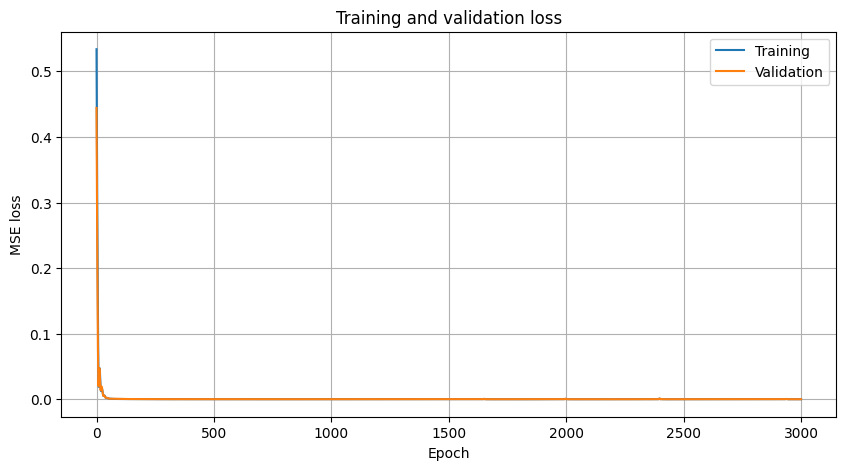

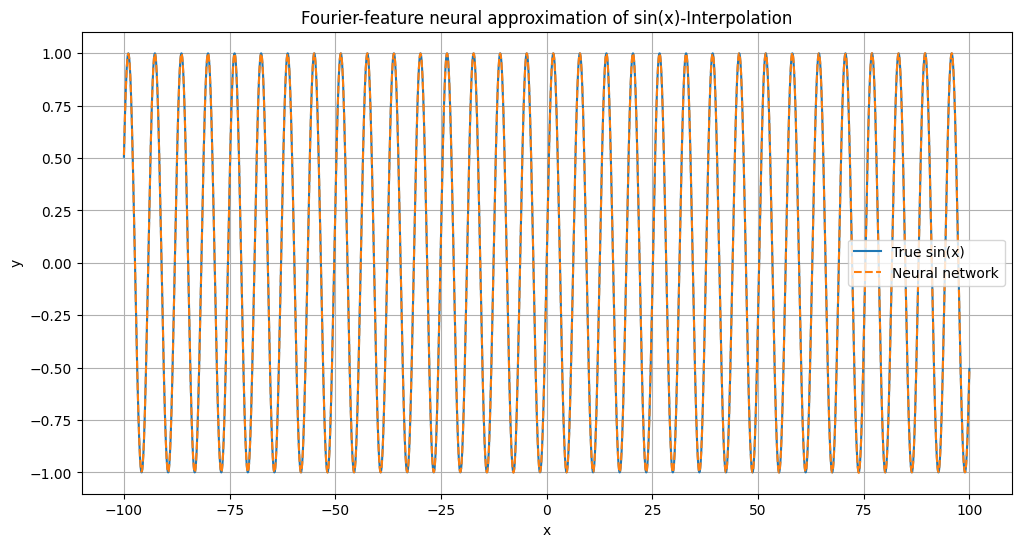

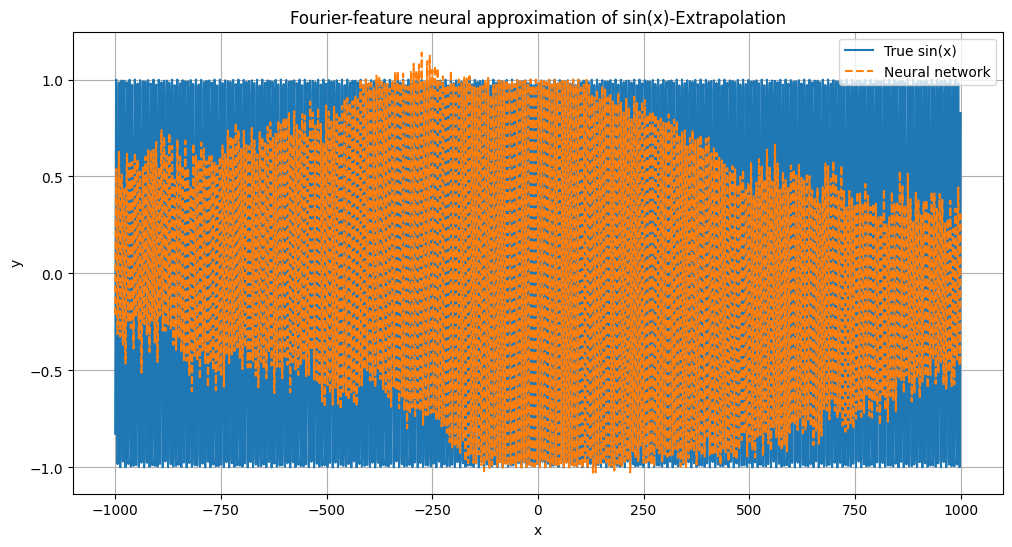

In [12]:
# ---------------------------------------------------------------------------
# Plots
# ---------------------------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)

plt.figure(figsize=(12, 6))
plt.plot(x_test.numpy(), y_test.numpy(), label="True sin(x)")
plt.plot(x_test.numpy(), predictions.numpy(), "--", label="Neural network")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Fourier-feature neural approximation of sin(x)-Interpolation")
plt.legend()
plt.grid(True)


plt.figure(figsize=(12, 6))
plt.plot(x_test_extrapolation.numpy(), y_test_extrapolation.numpy(), label="True sin(x)")
plt.plot(x_test_extrapolation.numpy(), predictions_extrapolation.numpy(), "--", label="Neural network")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Fourier-feature neural approximation of sin(x)-Extrapolation")
plt.legend()
plt.grid(True)

plt.show()